# Heuers' statistical Football model

The following implementation aims to recreate the Football model of Prof. Dr. Andreas Heuer.

In [132]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from functools import cache

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
SEED = 1893

np.random.seed(SEED)

In [133]:
# Helperfunctions
def plot_per_season_per_country(df, y, fit_reg=True):
    seasons = [14, 15, 16, 17, 18]
    sns.lmplot(x="season", y=y,
               hue="country", data=df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    sumed_df = pd.DataFrame()
    sumed_df["season"] = seasons
    total = []
    for season in seasons:
        total.append(np.sum(df.groupby(["season"]).get_group(
            season)[y]) / NUM_OF_COUNTRIES)
    sumed_df[y] = total
    sns.lmplot(x="season", y=y,
               data=sumed_df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    plt.show()

def closed_form_solution(X, y):
    # alternative: np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))
    return np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))


## Step 1 - Homefieldadvantage (per country and season)

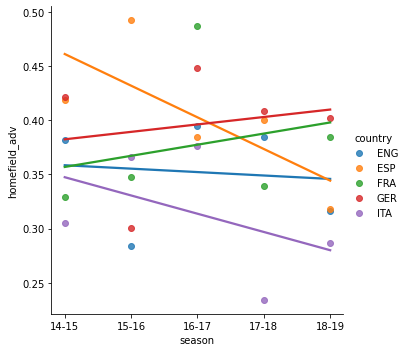

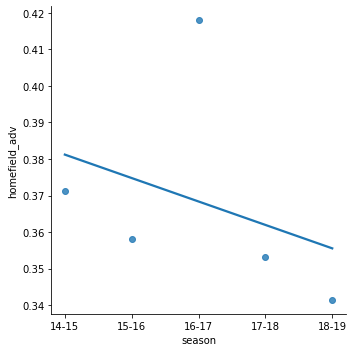

In [134]:
df_homefield = pd.read_csv('data/plot_homefield_adv.csv', sep=';')
plot_per_season_per_country(df_homefield, y="homefield_adv")

Homefield advantage tends to have high variance, a clear trend per country or season is not visible.
Therefor homefield advantage will be modeled as an constant of the average of hometeamgoals - awayteamgoals

In [135]:
avg_homefield_adv = np.sum(df_homefield["homefield_adv"]) / NUM_OF_SEASONS
print("Average homefield advantage on all games:", avg_homefield_adv)


Average homefield advantage on all games: 0.36837358101135187


In [136]:
df_country_season_homefield_adv = pd.read_csv(
    "data/country_season_homefield_adv.csv", sep=";")
df_country_season_homefield_adv['bias'] = 1

noise = np.random.normal(
    avg_homefield_adv, 0.01, df_country_season_homefield_adv.shape[0] * 3)

for index, row in df_country_season_homefield_adv.iterrows():
    if row["hf_adv_actual"] == 0:
        df_country_season_homefield_adv.at[index,
                                           "hf_adv_actual"] = noise[index]
    if row["hf_adv_current_season"] == 0:
        df_country_season_homefield_adv.at[index,
                                           "hf_adv_current_season"] = noise[df_country_season_homefield_adv.shape[0] + index]
    if row["hf_adv_last_three_seasons"] == 0:
        df_country_season_homefield_adv.at[index,
                                           "hf_adv_last_three_seasons"] = noise[df_country_season_homefield_adv.shape[0] * 2 + index]

df_country_season_homefield_adv


,country,season,matchnumber,hf_adv_last_three_seasons,hf_adv_current_season,hf_adv_actual,bias
0,ENG,14,1,0.360328,-0.300000,-0.6,1
1,ENG,14,2,0.369811,0.033333,0.7,1
2,ENG,14,3,0.357811,-0.075000,-0.4,1
3,ENG,14,4,0.357465,0.060000,0.6,1
4,ENG,14,5,0.361030,0.016667,-0.2,1
...,...,...,...,...,...,...,...
925,ITA,18,34,0.317094,0.262857,0.5,1
926,ITA,18,35,0.317094,0.247222,-0.3,1
927,ITA,18,36,0.317094,0.248649,0.3,1
928,ITA,18,37,0.317094,0.268421,1.0,1


In [137]:
@cache
def h_country_season_homefield_adv(country, season, matchnumber):
    if season == 14 and matchnumber == 1:
        return avg_homefield_adv
        
    sub_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and (season < {season} or (season == {season} and matchnumber < {matchnumber}))")

    X = sub_df[["hf_adv_last_three_seasons",
                "hf_adv_current_season"]].values # no bias
    y = sub_df["hf_adv_actual"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["hf_adv_last_three_seasons",
                      "hf_adv_current_season"]].values

    return np.dot(w, input.T)[0]


print("Homefield advantage:", h_country_season_homefield_adv("ESP", 14, 2))


Homefield advantage: 1.0666666666666667


## Step 2 - Goalamount per match (per country and season)

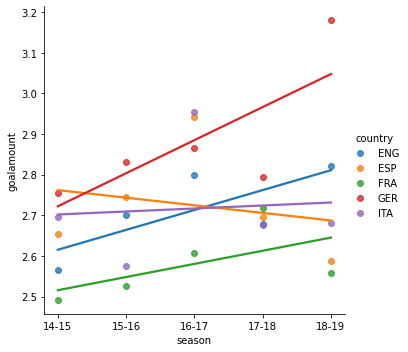

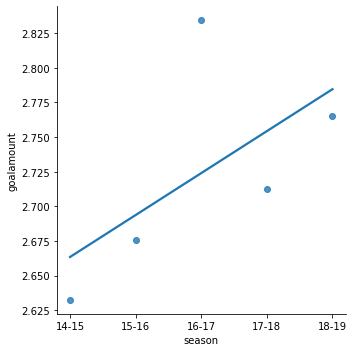

In [138]:
df_goalamount = pd.read_csv('data/plot_goalamount.csv', sep=';')
plot_per_season_per_country(df_goalamount, "goalamount")

there are higher scored countrys as well as lower scoring ones
for now the goalamount will be modeled as a constant

In [139]:
avg_goalamount = np.sum(df_goalamount["goalamount"]) / NUM_OF_SEASONS
print("Average goalamount of all games:", avg_goalamount)

Average goalamount of all games: 2.724046095631235


In [140]:
df_country_season_goalamount = pd.read_csv(
    "data/country_season_goalamount.csv", sep=";")
df_country_season_goalamount['bias'] = 1

noise = np.random.normal(
    avg_goalamount, 0.01, df_country_season_goalamount.shape[0] * 3)


for index, row in df_country_season_goalamount.iterrows():
    if row["ga_actual"] == 0:
        df_country_season_goalamount.at[index, "ga_actual"] = noise[index]
    if row["ga_current_season"] == 0:
        df_country_season_goalamount.at[index,
                                        "ga_current_season"] = noise[df_country_season_goalamount.shape[0] + index]
    if row["ga_last_three_seasons"] == 0:
        df_country_season_goalamount.at[index,
                                        "ga_last_three_seasons"] = noise[df_country_season_goalamount.shape[0] * 2 + index]

df_country_season_goalamount


,country,season,matchnumber,ga_last_three_seasons,ga_current_season,ga_actual,bias
0,ENG,14,1,2.724707,2.711666,2.6,1
1,ENG,14,2,2.738289,2.600000,2.3,1
2,ENG,14,3,2.712757,2.450000,3.2,1
3,ENG,14,4,2.738602,2.700000,3.0,1
4,ENG,14,5,2.727393,2.775000,3.2,1
...,...,...,...,...,...,...,...
925,ITA,18,34,2.735965,2.663636,2.3,1
926,ITA,18,35,2.735965,2.652941,2.9,1
927,ITA,18,36,2.735965,2.660000,3.1,1
928,ITA,18,37,2.735965,2.672222,2.8,1


In [141]:
@cache
def h_country_season_goalamount(country, season, matchnumber):
    if season == 14 and matchnumber == 1:
        return avg_goalamount

    sub_df = df_country_season_goalamount.query(
        f"country == '{country}' and (season < {season} or (season == {season} and matchnumber < {matchnumber}))")

    X = sub_df[["ga_last_three_seasons",
                "ga_current_season"]].values # no bias
    y = sub_df["ga_actual"].values

    w = closed_form_solution(X, y)
    # print("weights:", w)

    input_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["ga_last_three_seasons",
                      "ga_current_season"]].values

    return np.dot(w, input.T)[0]


print("Goalamount:", h_country_season_goalamount("GER", 16, 1))


Goalamount: 2.936261991159674


## Step 3: Teamstrength and expected goaldifference

In the first season (14/15) every team is treated promoter.

In [142]:
df_matches = pd.read_csv('data/matches.csv', sep=';')
df_matches['bias'] = 1

noise = np.random.normal(0, 0.01, df_matches.shape[0] * 5)

for index, row in df_matches.iterrows():
    if row["curr_chancediff"] == 0:
        df_matches.at[index, "curr_chancediff"] = noise[index]
    if row["past_chancediff_combined"] == 0:
        df_matches.at[index,
                           "past_chancediff_combined"] = noise[df_matches.shape[0] + index]
    if row["past_chanceamount"] == 0:
        df_matches.at[index,
                           "past_chanceamount"] = noise[df_matches.shape[0] * 2 + index]
    if row["actual_goaldiff"] == 0:
        df_matches.at[index,
                           "actual_goaldiff"] = noise[df_matches.shape[0] * 3 + index]
    if row["actual_goalamount"] == 0:
        df_matches.at[index,
                           "actual_goalamount"] = noise[df_matches.shape[0] * 4 + index]

df_matches


,country,season,matchnumber,teamname,curr_chancediff,past_chancediff_combined,past_chanceamount,market_value_ln_relative,actual_goalamount,actual_goaldiff,bias
0,ENG,14,1,Queens Park Rangers,-0.005861,-0.006476,0.017177,-0.392415,1,-1,1
1,ENG,14,1,Hull,-0.001357,-0.016237,-0.001372,-0.348740,1,1,1
2,ENG,14,1,Newcastle,-0.017697,-0.007620,-0.002578,-0.169272,2,-2,1
3,ENG,14,1,Man City,0.004003,-0.012178,0.001265,1.002768,2,2,1
4,ENG,14,1,Burnley,-0.004496,-0.007794,0.004065,-1.140622,4,-2,1
...,...,...,...,...,...,...,...,...,...,...,...
18255,ITA,18,38,Napoli,3.526316,5.293421,337.333333,1.070083,5,-1,1
18256,ITA,18,38,Inter,2.210526,2.380263,256.666667,1.024225,3,1,1
18257,ITA,18,38,Empoli,-2.421053,-3.058772,167.333333,-0.738824,3,-1,1
18258,ITA,18,38,Cagliari,-2.578947,-1.972368,183.333333,-0.358838,3,-1,1


In [143]:
@cache
def h_teamstrength(country, season, matchnumber, teamname):
    if season == 14 and matchnumber == 1:
        # avg teamstrength
        return 0

    sub_df = df_matches.query(
        f"country == '{country}' and (season < {season} or (season == {season} and matchnumber < {matchnumber}))")

    X = sub_df[["past_chancediff_combined",
                "curr_chancediff", "market_value_ln_relative"]].values # no bias
    y = sub_df["actual_goaldiff"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_matches.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chancediff_combined",
                      "curr_chancediff", "market_value_ln_relative"]].values 

    return np.dot(w, input.T)[0]

#TODO: Homefield adv correction
#TODO: Effective chancediff
#TODO: Current fitness value is missing 
#TODO: Verwertungsfaktor on chancediff is missing

print("Teamstrength:", h_teamstrength("ENG", 16, 30, "Liverpool"))


Teamstrength: 0.7709481622057779


## Step 4: Specialty for promoters

In [144]:
#TODO: Implement special correction of teamstrength for promoters

## Step 5: Expected goalamount per match

In [145]:
@cache
def h_goalamount_from_avg_per_match(country, season, matchnumber, teamname):
    if season == 14 and matchnumber == 1:
        # avg goalamount from avg
        return 0

    sub_df = df_matches.query(
        f"country == '{country}' and (season < {season} or (season == {season} and matchnumber < {matchnumber}))")

    X = sub_df[["past_chanceamount"]].values # no bias
    y = []
    for index, row in sub_df.iterrows():
        y.append(row["actual_goalamount"] - h_country_season_goalamount(country, season, row["matchnumber"]))

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_matches.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chanceamount"]].values

    return np.dot(w, input.T)[0]

#TODO: Homefield adv correction
#TODO: Effective chancediff missing

print("Goalamount from avg:", h_goalamount_from_avg_per_match("GER", 16, 2, "Bayern"))


Goalamount from avg: -0.012195086992879385


## Step 6: Predicted Goals

In [146]:
def predicted_goals(country, season, matchnumber, hometeam, awayteam):
    goalamount = h_goalamount_from_avg_per_match(
        country, season, matchnumber, hometeam) + h_goalamount_from_avg_per_match(country, season, matchnumber, awayteam) + h_country_season_goalamount(country, season, matchnumber)
    goaldiff = h_country_season_homefield_adv(country, season, matchnumber) + h_teamstrength(country, season, matchnumber, hometeam) - h_teamstrength(country, season, matchnumber, awayteam)
    return (goalamount, goaldiff)

country, season, matchnumber, hometeam, awayteam = "GER", 18, 20, "Bayern", "Freiburg"

amount, diff = predicted_goals(
    country, season, matchnumber, hometeam, awayteam)

if diff < 0:
    home_score = (amount - diff) / 2
    away_score = home_score + (-diff)
else:
    away_score = (amount - diff) / 2
    home_score = away_score + diff

print(f"Prediction of {country}, {season}, {matchnumber}; {hometeam} vs. {awayteam}:",
      str(home_score)[0:4] + " : " + str(away_score)[0:4])


Prediction of GER, 18, 20; Bayern vs. Freiburg: 2.45 : 0.43


## Step 7: Dependence on matchnumber

In [147]:
def matchnumber_goalamount_multiplier(country, matchnumber):
    # Uncertain
    if country == 'GER':
        if matchnumber < 18:
            return 1.02
        elif matchnumber < 31:
            return 0.95
        else:
            return 1.2
    else:
        if matchnumber < 19:
            return 1.02
        elif matchnumber < 35:
            return 0.95
        else:
            return 1.2


## Final: Full run on dataset to measure goalamount and goaldifference error

In [148]:
def predict(country, season, matchnumber, hometeam, awayteam):
    amount, diff = predicted_goals(country, season, matchnumber, hometeam, awayteam)

    if diff < 0:
        home_score = (amount - diff) / 2
        away_score = home_score + (-diff)
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    home_score *= matchnumber_goalamount_multiplier(country, matchnumber)
    away_score *= matchnumber_goalamount_multiplier(country, matchnumber)

    return f"{str(home_score)[0:4 if home_score >= 0 else 5]} : {str(away_score)[0:4 if away_score >= 0 else 5]}"


country, season, matchnumber, hometeam, awayteam = "ENG", 17, 6, "Man City", "Crystal Palace"

print(f"Prediction {country} {season} {matchnumber} {hometeam} - {awayteam}:",
      predict(country, season, matchnumber, hometeam, awayteam))


Prediction ENG 17 6 Man City - Crystal Palace: 2.30 : 0.49


In [149]:
# For match in Dataset run prediction and measure error
do_a_whole_run = True

if do_a_whole_run:
    for index, row in df_matches.iterrows():
        if index % 2 == 0:
            hometeam = row["teamname"]
            continue
        else:
            awayteam = row["teamname"]
            print(row["country"], row["season"], row["matchnumber"], hometeam, awayteam, predict(
                row["country"], row["season"], row["matchnumber"], hometeam, awayteam))


ENG 14 1 Queens Park Rangers Hull 1.57 : 1.20
ENG 14 1 Newcastle Man City 1.57 : 1.20
ENG 14 1 Burnley Chelsea 1.57 : 1.20
ENG 14 1 Arsenal Crystal Palace 1.57 : 1.20
ENG 14 1 West Ham Tottenham 1.57 : 1.20
ENG 14 1 Leicester Everton 1.57 : 1.20
ENG 14 1 Man Utd Swansea 1.57 : 1.20
ENG 14 1 West Brom Sunderland 1.57 : 1.20
ENG 14 1 Liverpool Southampton 1.57 : 1.20
ENG 14 1 Stoke Aston Villa 1.57 : 1.20
ENG 14 2 Sunderland Man Utd 2.52 : 4.96
ENG 14 2 Aston Villa Newcastle 2.97 : -0.75
ENG 14 2 Tottenham Queens Park Rangers 1.94 : 0.74
ENG 14 2 Swansea Burnley 2.05 : 0.38
ENG 14 2 Hull Stoke 1.55 : 2.32
ENG 14 2 Southampton West Brom 1.25 : 1.34
ENG 14 2 Everton Arsenal 2.83 : 5.94
ENG 14 2 Crystal Palace West Ham 2.27 : 4.12
ENG 14 2 Chelsea Leicester 3.02 : -0.51
ENG 14 2 Man City Liverpool 3.31 : -1.03
ENG 14 3 West Ham Southampton 1.03 : 0.98
ENG 14 3 Burnley Man Utd 2.28 : 4.69
ENG 14 3 Swansea West Brom 1.62 : 0.96
ENG 14 3 Man City Stoke 2.12 : 0.02
ENG 14 3 Leicester Arsenal 2.